In [18]:
import os
import shutil
import random
from pathlib import Path
from PIL import Image
import numpy as np 
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

In [19]:
# Paths
input_root = "/kaggle/input/cxr-ct-cough/processed_dataset/processed_dataset"
output_root = "/kaggle/working/processed_dataset_split"
splits = {'train': 400, 'valid': 50, 'test': 50}
modalities = ["CT", "CXR", "Cough sound"]
classes = ["Healthy", "Lungs Cancer", "Pneumonia", "covid"]

# Create output directories
for split in splits:
    for modality in modalities:
        for cls in classes:
            os.makedirs(os.path.join(output_root, split, modality, cls.replace(" ", "")), exist_ok=True)

# Split & rename images
for modality in modalities:
    for cls in classes:
        cls_clean = cls.replace(" ", "")
        input_folder = os.path.join(input_root, modality, cls_clean)
        all_images = list(Path(input_folder).glob("*.[jp][pn]g"))

        if len(all_images) < 500:
            raise ValueError(f"❌ Not enough images in {input_folder}. Found {len(all_images)}")

        random.shuffle(all_images)
        split_images = {
            'train': all_images[:splits['train']],
            'valid': all_images[splits['train']:splits['train'] + splits['valid']],
            'test': all_images[splits['train'] + splits['valid']:]
        }

        for split, img_paths in split_images.items():
            for idx, img_path in enumerate(img_paths, 1):
                img = Image.open(img_path).convert("RGB")
                new_name = f"{cls_clean}{idx}.jpg"
                save_path = os.path.join(output_root, split, modality, cls_clean, new_name)
                img.save(save_path)

In [20]:
DATASET_ROOT = "/kaggle/working/processed_dataset_split"
# Define the modality we are training on for this model
MODALITY = "CT"

# Model and training parameters
IMG_SIZE = 224 
BATCH_SIZE = 32
EPOCHS = 15 
NUM_CLASSES = 4 # Healthy, Lungs Cancer, Pneumonia, covid

In [21]:
# Define paths for each data split
train_dir = f"{DATASET_ROOT}/train/{MODALITY}"
valid_dir = f"{DATASET_ROOT}/valid/{MODALITY}"
test_dir = f"{DATASET_ROOT}/test/{MODALITY}"

In [22]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels='inferred',
    label_mode='int', # Use integers for labels (0, 1, 2, 3)
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True
)

Found 1600 files belonging to 4 classes.


This is a keras method that is ready to use to get the image dataset from directory I will use OS method later but I wanted to try this 

In [23]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    labels='inferred',
    label_mode='int',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False # No need to shuffle validation data
)

Found 200 files belonging to 4 classes.


In [24]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels='inferred',
    label_mode='int',
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False # No need to shuffle test data
)

Found 200 files belonging to 4 classes.


In [25]:
class_names = train_ds.class_names
print(f"Found classes: {class_names}")

Found classes: ['Healthy', 'LungsCancer', 'Pneumonia', 'covid']


In [26]:
preprocess_input = tf.keras.applications.resnet50.preprocess_input
def preprocess(image, label):
    return preprocess_input(image), label

train_ds = train_ds.map(preprocess).cache().prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.map(preprocess).cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.map(preprocess).cache().prefetch(buffer_size=tf.data.AUTOTUNE)

In [27]:
base_model = ResNet50(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False, 
    weights='imagenet'
)

In [28]:
base_model.trainable = False

# Create our new classification head on top of the frozen base model
inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x) # Flattens the feature maps
x = layers.Dropout(0.3)(x) # Add dropout for regularization
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x) # Our final layer for 4 classes

In [29]:
model = keras.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [30]:
model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy', # Use this loss for integer labels
    metrics=['accuracy']
)


checkpoint_path = "ct_only_model_best.keras"
checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_path,
    save_weights_only=False,
    monitor='val_accuracy',
    mode='max',
    save_best_only=True,
    verbose=1
)


In [31]:
print("Starting training...")
history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=[checkpoint_callback]
)

Starting training...
Epoch 1/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.5315 - loss: 1.1803
Epoch 1: val_accuracy improved from -inf to 0.88000, saving model to ct_only_model_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 258ms/step - accuracy: 0.5342 - loss: 1.1731 - val_accuracy: 0.8800 - val_loss: 0.3209
Epoch 2/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.8362 - loss: 0.4225
Epoch 2: val_accuracy improved from 0.88000 to 0.91000, saving model to ct_only_model_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 133ms/step - accuracy: 0.8366 - loss: 0.4216 - val_accuracy: 0.9100 - val_loss: 0.2254
Epoch 3/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.8828 - loss: 0.3198
Epoch 3: val_accuracy improved from 0.91000 to 0.91500, saving model to ct_only_model_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 139ms/step - accuracy: 0.8830 - loss: 0.3194 - val_accuracy: 0.9150 - val_loss: 0.1901
Epoch 4/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.8928 - loss: 0.

In [32]:
best_model = models.load_model(checkpoint_path)


loss, accuracy = best_model.evaluate(test_ds)
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Loss: {loss:.4f}")


y_pred_probs = best_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.concatenate([y for x, y in test_ds], axis=0)


7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 332ms/step - accuracy: 0.9487 - loss: 0.1363
Test Accuracy: 0.9600
Test Loss: 0.1167
7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 784ms/step


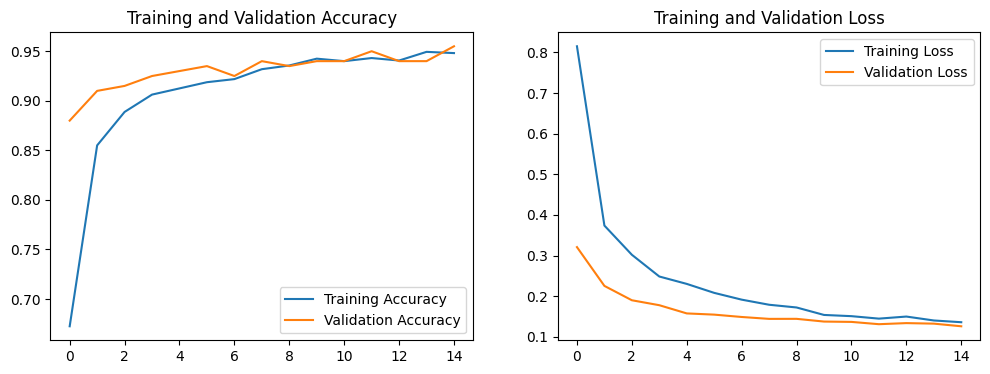

In [33]:
def plot_training_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 4))
    
    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.show()

# Usage:
plot_training_history(history)

In [34]:
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))


Classification Report:
              precision    recall  f1-score   support

     Healthy       0.94      0.90      0.92        50
 LungsCancer       1.00      1.00      1.00        50
   Pneumonia       1.00      1.00      1.00        50
       covid       0.90      0.94      0.92        50

    accuracy                           0.96       200
   macro avg       0.96      0.96      0.96       200
weighted avg       0.96      0.96      0.96       200




Confusion Matrix:


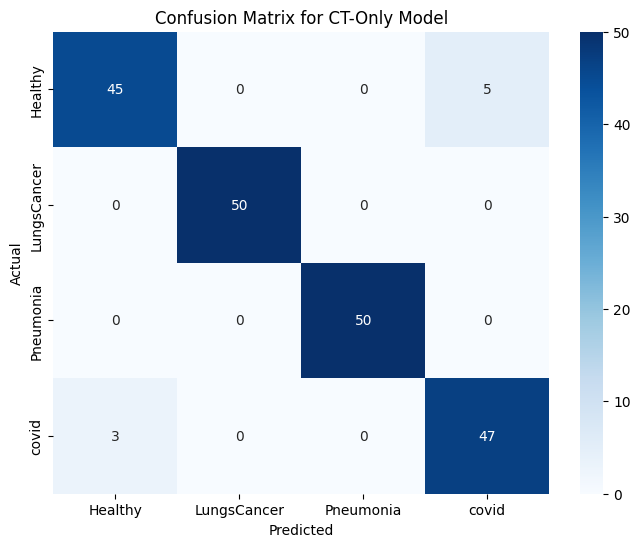

In [35]:
print("\nConfusion Matrix:")
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix for CT-Only Model')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

### Second model

In [36]:
MODALITY = "CXR" 
train_dir = f"{DATASET_ROOT}/train/{MODALITY}"
valid_dir = f"{DATASET_ROOT}/valid/{MODALITY}"
test_dir = f"{DATASET_ROOT}/test/{MODALITY}"

print(f"Loading datasets for modality: {MODALITY}...")

Loading datasets for modality: CXR...


In [37]:
class_to_label = {name: i for i, name in enumerate(class_names)}

def get_paths_and_labels(data_dir):
    """Walks a directory and returns lists of image paths and integer labels."""
    image_paths = []
    image_labels = []
    for class_name in class_names:
        class_dir = os.path.join(data_dir, class_name)
        # Check if the directory exists to avoid errors
        if os.path.isdir(class_dir):
            for filepath in os.listdir(class_dir):
                image_paths.append(os.path.join(class_dir, filepath))
                image_labels.append(class_to_label[class_name])
    return image_paths, image_labels

In [38]:
train_paths, train_labels = get_paths_and_labels(train_dir)
val_paths, val_labels = get_paths_and_labels(valid_dir)
test_paths, test_labels = get_paths_and_labels(test_dir)

In [39]:
reprocess_input = tf.keras.applications.resnet50.preprocess_input

def load_and_preprocess_image(path, label):
    """Loads an image file, decodes it, resizes, and preprocesses it."""
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = preprocess_input(image)
    return image, label

In [40]:
def create_dataset(paths, labels):
    """Creates a configured tf.data.Dataset from file paths and labels."""
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.cache().batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)
    return ds

In [41]:
train_ds = create_dataset(train_paths, train_labels).shuffle(buffer_size=len(train_paths))
val_ds = create_dataset(val_paths, val_labels)
test_ds = create_dataset(test_paths, test_labels)

In [42]:
print("Building model with ResNet50 base...")
base_model = ResNet50(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
model = keras.Model(inputs, outputs)

Building model with ResNet50 base...


In [43]:
model.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [44]:
checkpoint_path = "cxr_only_model_best.keras"
checkpoint_callback = ModelCheckpoint(filepath=checkpoint_path,
                                      save_weights_only=False,
                                      monitor='val_accuracy',
                                      mode='max',
                                      save_best_only=True,
                                      verbose=1)

print("Starting CXR model training...")
history = model.fit(train_ds,
                    epochs=EPOCHS,
                    validation_data=val_ds,
                    callbacks=[checkpoint_callback])

Starting CXR model training...
Epoch 1/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.2827 - loss: 2.4609
Epoch 1: val_accuracy improved from -inf to 0.73500, saving model to cxr_only_model_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 247ms/step - accuracy: 0.2860 - loss: 2.4450 - val_accuracy: 0.7350 - val_loss: 0.8320
Epoch 2/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.6677 - loss: 0.8809
Epoch 2: val_accuracy improved from 0.73500 to 0.85500, saving model to cxr_only_model_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 133ms/step - accuracy: 0.6691 - loss: 0.8765 - val_accuracy: 0.8550 - val_loss: 0.3470
Epoch 3/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.8468 - loss: 0.4155
Epoch 3: val_accuracy improved from 0.85500 to 0.89000, saving model to cxr_only_model_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 141ms/step - accuracy: 0.8463 - loss: 0.4162 - val_accuracy: 0.8900 - val_loss: 0.3012
Epoch 4/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.81

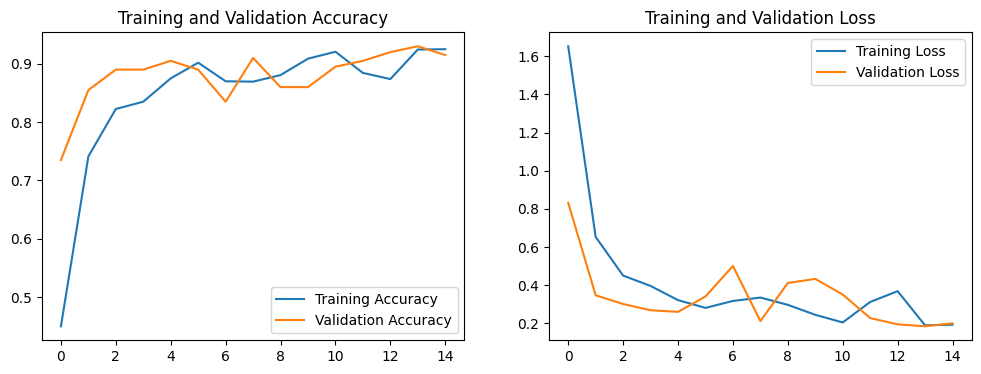

In [45]:
plot_training_history(history)

In [46]:
best_model = models.load_model(checkpoint_path)

# Get final loss and accuracy
loss, accuracy = best_model.evaluate(test_ds)
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Loss: {loss:.4f}")

# Get predictions and true labels for detailed metrics
y_pred_probs = best_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
# Correct way to get true labels from a tf.data.Dataset
y_true = np.concatenate([y for x, y in test_ds], axis=0)


7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 321ms/step - accuracy: 0.8433 - loss: 0.3244
Test Accuracy: 0.9000
Test Loss: 0.2227
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 798ms/step


In [47]:
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

              precision    recall  f1-score   support

     Healthy       0.94      0.68      0.79        50
 LungsCancer       1.00      1.00      1.00        50
   Pneumonia       0.94      0.96      0.95        50
       covid       0.76      0.96      0.85        50

    accuracy                           0.90       200
   macro avg       0.91      0.90      0.90       200
weighted avg       0.91      0.90      0.90       200




Confusion Matrix:


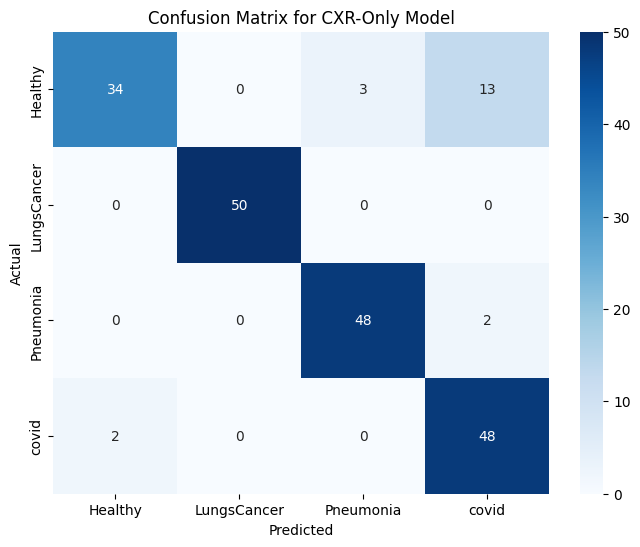

In [48]:
print("\nConfusion Matrix:")
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix for CXR-Only Model')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

### Third model

In [49]:
MODALITY = "Cough sound"
EPOCHS = 15

train_dir = f"{DATASET_ROOT}/train/{MODALITY}"
valid_dir = f"{DATASET_ROOT}/valid/{MODALITY}"
test_dir = f"{DATASET_ROOT}/test/{MODALITY}"

print(f"Loading datasets for modality: {MODALITY}...")
class_names = ["Healthy", "LungsCancer", "Pneumonia", "covid"]
class_to_label = {name: i for i, name in enumerate(class_names)}
NUM_CLASSES = len(class_names)

Loading datasets for modality: Cough sound...


In [50]:
train_paths, train_labels = get_paths_and_labels(train_dir)
val_paths, val_labels = get_paths_and_labels(valid_dir)
test_paths, test_labels = get_paths_and_labels(test_dir)

In [51]:
train_ds = create_dataset(train_paths, train_labels).shuffle(buffer_size=len(train_paths))
val_ds = create_dataset(val_paths, val_labels)
test_ds = create_dataset(test_paths, test_labels)

In [52]:
base_model = ResNet50(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
model = keras.Model(inputs, outputs)

In [53]:
model.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Use a new checkpoint path for this model
checkpoint_path = "cough_sound_model_best.keras"
checkpoint_callback = ModelCheckpoint(filepath=checkpoint_path,
                                      monitor='val_accuracy',
                                      mode='max',
                                      save_best_only=True,
                                      verbose=1)

In [54]:
history = model.fit(train_ds,
                    epochs=EPOCHS,
                    validation_data=val_ds,
                    callbacks=[checkpoint_callback])

Epoch 1/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.3696 - loss: 1.9745
Epoch 1: val_accuracy improved from -inf to 0.71000, saving model to cough_sound_model_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 247ms/step - accuracy: 0.3713 - loss: 1.9664 - val_accuracy: 0.7100 - val_loss: 0.7257
Epoch 2/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.6988 - loss: 0.8970
Epoch 2: val_accuracy improved from 0.71000 to 0.72000, saving model to cough_sound_model_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 135ms/step - accuracy: 0.6989 - loss: 0.8965 - val_accuracy: 0.7200 - val_loss: 0.8827
Epoch 3/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.7120 - loss: 0.7719
Epoch 3: val_accuracy did not improve from 0.72000
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 124ms/step - accuracy: 0.7122 - loss: 0.7706 - val_accuracy: 0.6850 - val_loss: 0.9275
Epoch 4/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.7283 - loss: 0.7739
Epoch 4: val_accuracy improved from 0.72000 to 0.76000

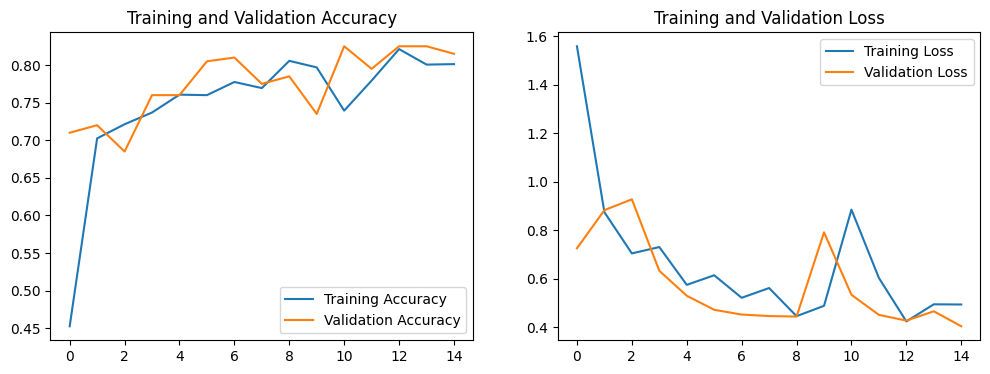

In [55]:
plot_training_history(history)

In [56]:
best_model = models.load_model(checkpoint_path)

loss, accuracy = best_model.evaluate(test_ds)

7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 332ms/step - accuracy: 0.9287 - loss: 0.2706


In [57]:
y_pred_probs = best_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.concatenate([y for x, y in test_ds], axis=0)

7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 893ms/step


In [58]:
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

              precision    recall  f1-score   support

     Healthy       0.65      0.98      0.78        50
 LungsCancer       0.94      1.00      0.97        50
   Pneumonia       0.96      1.00      0.98        50
       covid       0.95      0.38      0.54        50

    accuracy                           0.84       200
   macro avg       0.88      0.84      0.82       200
weighted avg       0.88      0.84      0.82       200



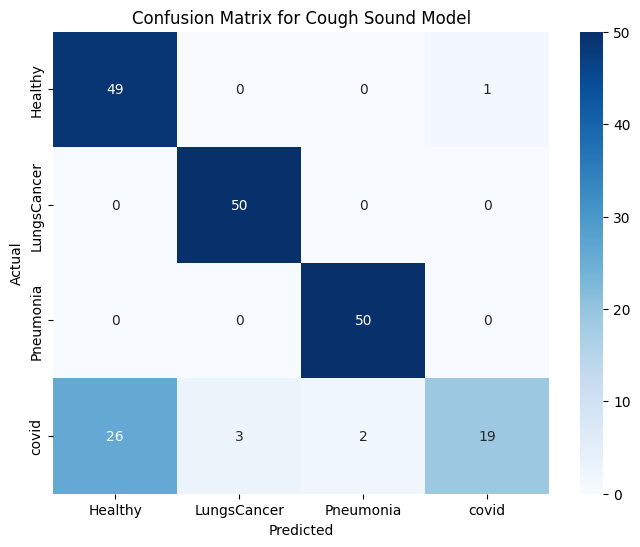

In [59]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix for Cough Sound Model')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

### Fourth model 

In [60]:
MODALITIES = ["CT", "CXR", "Cough sound"]
EPOCHS = 20 
CLASS_NAMES = ["Healthy", "LungsCancer", "Pneumonia", "covid"]
CLASS_TO_LABEL = {name: i for i, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

In [61]:
def get_multimodal_paths_and_labels(split_dir):
    """
    Finds corresponding image paths for all modalities and their labels,
    ensuring the files are sorted to maintain alignment.
    """
    paths_ct, paths_cxr, paths_cough = [], [], []
    labels = []

    for class_name in CLASS_NAMES:
        base_modality_dir = os.path.join(split_dir, MODALITIES[0], class_name)
        if not os.path.isdir(base_modality_dir):
            continue
        
        sorted_filenames = sorted(os.listdir(base_modality_dir))

        for filename in sorted_filenames:
            path_ct = os.path.join(split_dir, MODALITIES[0], class_name, filename)
            path_cxr = os.path.join(split_dir, MODALITIES[1], class_name, filename)
            path_cough = os.path.join(split_dir, MODALITIES[2], class_name, filename)

            if os.path.exists(path_cxr) and os.path.exists(path_cough):
                paths_ct.append(path_ct)
                paths_cxr.append(path_cxr)
                paths_cough.append(path_cough)
                labels.append(CLASS_TO_LABEL[class_name])

    return (paths_ct, paths_cxr, paths_cough), labels

In [62]:
def load_and_preprocess(path_ct, path_cxr, path_cough, label):
    """
    Loads and preprocesses the three images for a single sample, returning
    a dictionary that maps input names to image tensors.
    """
    def _process_one_image(path):
        image = tf.io.read_file(path)
        image = tf.image.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
        image = image / 255.0  # Normalize to [0, 1]
        return image

    img_ct = _process_one_image(path_ct)
    img_cxr = _process_one_image(path_cxr)
    img_cough = _process_one_image(path_cough)

    # Return a dictionary matching the model's input layer names
    return {"input_ct": img_ct, "input_cxr": img_cxr, "input_cough": img_cough}, label

In [63]:
def create_multimodal_dataset(paths, labels):
    """Creates a tf.data.Dataset from the file paths and labels."""
    ds = tf.data.Dataset.from_tensor_slices((paths[0], paths[1], paths[2], labels))
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)
    return ds

In [64]:
print("Preparing datasets...")
train_paths, train_labels = get_multimodal_paths_and_labels(os.path.join(DATASET_ROOT, 'train'))
val_paths, val_labels = get_multimodal_paths_and_labels(os.path.join(DATASET_ROOT, 'valid'))
test_paths, test_labels = get_multimodal_paths_and_labels(os.path.join(DATASET_ROOT, 'test'))

Preparing datasets...


In [65]:
train_ds = create_multimodal_dataset(train_paths, train_labels).shuffle(buffer_size=len(train_labels))
val_ds = create_multimodal_dataset(val_paths, val_labels)
test_ds = create_multimodal_dataset(test_paths, test_labels)
print("Datasets are ready.")

Datasets are ready.


In [66]:
print("Building the Early Fusion model...")
# Define the three separate inputs for each modality
input_shape = (IMG_SIZE, IMG_SIZE, 3)
input_ct = keras.Input(shape=input_shape, name="input_ct")
input_cxr = keras.Input(shape=input_shape, name="input_cxr")
input_cough = keras.Input(shape=input_shape, name="input_cough")

# Immediately concatenate the inputs along the channel axis (axis=-1).
# This is the "early fusion" step, creating a single 9-channel tensor.
concatenated_inputs = layers.concatenate([input_ct, input_cxr, input_cough])

Building the Early Fusion model...


In [67]:
x = layers.Conv2D(32, (3, 3), activation='relu')(concatenated_inputs)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(64, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(128, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)

# Flatten and add the final classification layers
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

In [68]:
model = models.Model(
    inputs=[input_ct, input_cxr, input_cough],
    outputs=outputs
)

In [69]:
model.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

checkpoint_path = "early_fusion_concat_layer_best.keras"
checkpoint_callback = ModelCheckpoint(filepath=checkpoint_path,
                                      monitor='val_accuracy',
                                      mode='max',
                                      save_best_only=True,
                                      verbose=1)

In [70]:
history = model.fit(train_ds,
                    epochs=EPOCHS,
                    validation_data=val_ds,
                    callbacks=[checkpoint_callback])

Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.2348 - loss: 1.4106
Epoch 1: val_accuracy improved from -inf to 0.43000, saving model to early_fusion_concat_layer_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 122ms/step - accuracy: 0.2350 - loss: 1.4105 - val_accuracy: 0.4300 - val_loss: 1.3553
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.3444 - loss: 1.3602
Epoch 2: val_accuracy improved from 0.43000 to 0.57500, saving model to early_fusion_concat_layer_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.3447 - loss: 1.3599 - val_accuracy: 0.5750 - val_loss: 1.3036
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.4651 - loss: 1.2869
Epoch 3: val_accuracy improved from 0.57500 to 0.63500, saving model to early_fusion_concat_layer_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.4648 - loss: 1.2868 - val_accuracy: 0.6350 - val_loss: 1.2119
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.5137 -

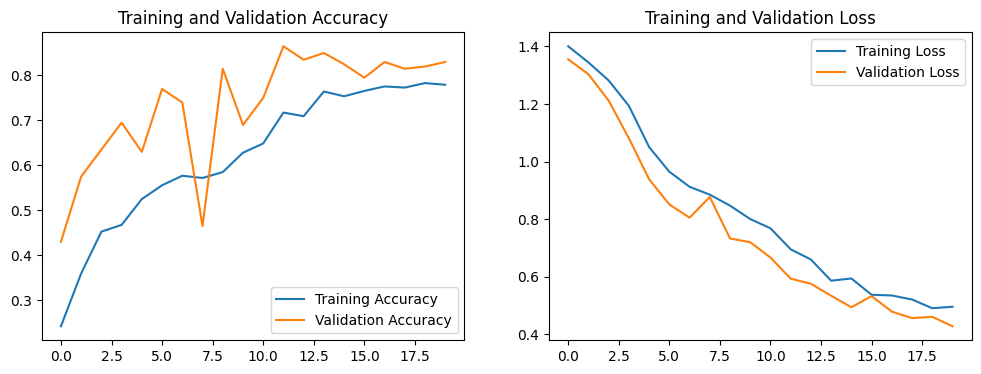

In [71]:
plot_training_history(history)

In [72]:
print("\nEvaluating the best model on the test set...")
best_model = models.load_model(checkpoint_path)


Evaluating the best model on the test set...


In [73]:
loss, accuracy = best_model.evaluate(test_ds)
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Loss: {loss:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.8168 - loss: 0.6243
Test Accuracy: 0.8450
Test Loss: 0.5850


In [74]:
y_pred_probs = best_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.concatenate([y for x, y in test_ds], axis=0)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step


In [75]:
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))


Classification Report:
              precision    recall  f1-score   support

     Healthy       0.76      0.68      0.72        50
 LungsCancer       0.94      1.00      0.97        50
   Pneumonia       0.94      1.00      0.97        50
       covid       0.71      0.70      0.71        50

    accuracy                           0.84       200
   macro avg       0.84      0.84      0.84       200
weighted avg       0.84      0.84      0.84       200




Confusion Matrix:


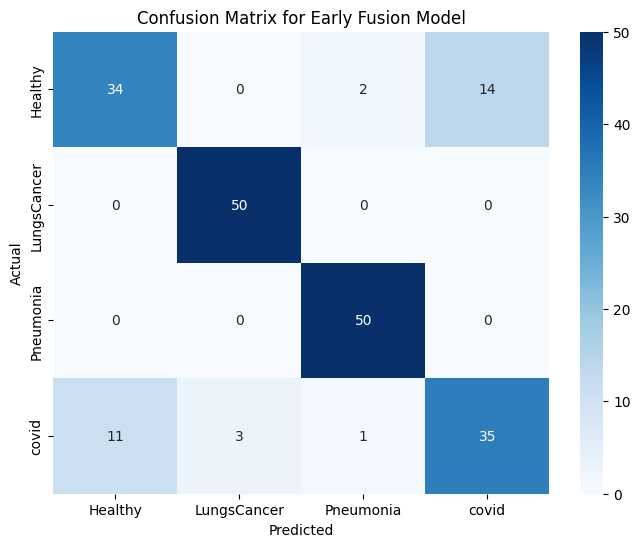

In [76]:
print("\nConfusion Matrix:")
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Confusion Matrix for Early Fusion Model')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

### Fifth model

In [77]:
EPOCHS = 15

train_paths, train_labels = get_multimodal_paths_and_labels(os.path.join(DATASET_ROOT, 'train'))
val_paths, val_labels = get_multimodal_paths_and_labels(os.path.join(DATASET_ROOT, 'valid'))
test_paths, test_labels = get_multimodal_paths_and_labels(os.path.join(DATASET_ROOT, 'test'))

In [78]:
def load_and_preprocess_late_fusion(path_ct, path_cxr, path_cough, label):
    """Loads images and applies the specific preprocessing for ResNet50."""
    def _process_one_image(path):
        image = tf.io.read_file(path)
        image = tf.image.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
        # IMPORTANT: Apply the ResNet50-specific preprocessing
        image = resnet_preprocess(image)
        return image

    img_ct = _process_one_image(path_ct)
    img_cxr = _process_one_image(path_cxr)
    img_cough = _process_one_image(path_cough)
    
    return {"input_ct": img_ct, "input_cxr": img_cxr, "input_cough": img_cough}, label

In [79]:
def create_multimodal_dataset(paths, labels):
    ds = tf.data.Dataset.from_tensor_slices((paths[0], paths[1], paths[2], labels))
    ds = ds.map(load_and_preprocess_late_fusion, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)
    return ds


In [80]:
train_ds = create_multimodal_dataset(train_paths, train_labels).shuffle(buffer_size=len(train_labels))
val_ds = create_multimodal_dataset(val_paths, val_labels)
test_ds = create_multimodal_dataset(test_paths, test_labels)


In [81]:

def create_feature_extractor_branch(name_prefix):
    """
    Creates a self-contained, frozen ResNet50 feature extractor model.
    This model takes an image as input and outputs a feature vector.
    """
    # Load the base ResNet50 model
    base_model = ResNet50(include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base_model.trainable = False

    # Define the input for this branch
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    
    # Preprocess the input specifically for ResNet50
    preprocessed_input = resnet_preprocess(inputs)

    # Get the feature maps from the frozen base model
    x = base_model(preprocessed_input, training=False)
    
    # Reduce features to a single vector
    outputs = layers.GlobalAveragePooling2D()(x)
    
    # Create the final branch model and give it a unique name
    branch_model = models.Model(inputs, outputs, name=f"{name_prefix}_feature_extractor")
    return branch_model


In [82]:
# 1. Create one self-contained feature extractor for each modality
ct_extractor = create_feature_extractor_branch("ct")
cxr_extractor = create_feature_extractor_branch("cxr")
cough_extractor = create_feature_extractor_branch("cough")


In [83]:
# 2. Define the three main inputs for the final fusion model
input_ct = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_ct")
input_cxr = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_cxr")
input_cough = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_cough")


In [84]:
# 3. Pass each input through its respective expert extractor model
features_ct = ct_extractor(input_ct)
features_cxr = cxr_extractor(input_cxr)
features_cough = cough_extractor(input_cough)

In [85]:
concatenated = layers.concatenate([features_ct, features_cxr, features_cough])

In [86]:
x = layers.Dense(256, activation='relu')(concatenated)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

In [87]:
model = models.Model(inputs=[input_ct, input_cxr, input_cough], outputs=outputs)

model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ct            │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_cxr           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_cough         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ct_feature_extract… │ (None, 2048)      │ 23,587,712 │ input_ct[0][0]    │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cxr_feature_extrac… │ (None, 2048)      │ 23,587,712 │ input_cxr[0][0]   │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cough_feature_extr… │ (None, 2048)      │ 23,587,712 │ input_cough[0][0] │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 6144)      │          0 │ ct_feature_extra… │
│ (Concatenate)       │                   │            │ cxr_feature_extr… │
│                     │                   │            │ cough_feature_ex… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 256)       │  1,573,120 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 256)       │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 4)         │      1,028 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 72,337,284 (275.94 MB)

 Trainable params: 1,574,148 (6.00 MB)

 Non-trainable params: 70,763,136 (269.94 MB)

In [88]:
model.compile(optimizer=keras.optimizers.AdamW(learning_rate=1e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

checkpoint_path = "late_fusion_model_best.keras"
checkpoint_callback = ModelCheckpoint(filepath=checkpoint_path,
                                      monitor='val_accuracy',
                                      mode='max',
                                      save_best_only=True,
                                      verbose=1)


In [89]:
history = model.fit(train_ds,
                    epochs=EPOCHS,
                    validation_data=val_ds,
                    callbacks=[checkpoint_callback])


Epoch 1/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step - accuracy: 0.3843 - loss: 2.5436
Epoch 1: val_accuracy improved from -inf to 0.75000, saving model to late_fusion_model_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 74s 719ms/step - accuracy: 0.3862 - loss: 2.5296 - val_accuracy: 0.7500 - val_loss: 0.5541
Epoch 2/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step - accuracy: 0.7150 - loss: 0.7383
Epoch 2: val_accuracy improved from 0.75000 to 0.88000, saving model to late_fusion_model_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 414ms/step - accuracy: 0.7164 - loss: 0.7340 - val_accuracy: 0.8800 - val_loss: 0.3025
Epoch 3/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - accuracy: 0.8958 - loss: 0.2924
Epoch 3: val_accuracy improved from 0.88000 to 0.91000, saving model to late_fusion_model_best.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 399ms/step - accuracy: 0.8955 - loss: 0.2925 - val_accuracy: 0.9100 - val_loss: 0.2280
Epoch 4/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step - accuracy: 0.8887 - loss: 0.2806
Ep

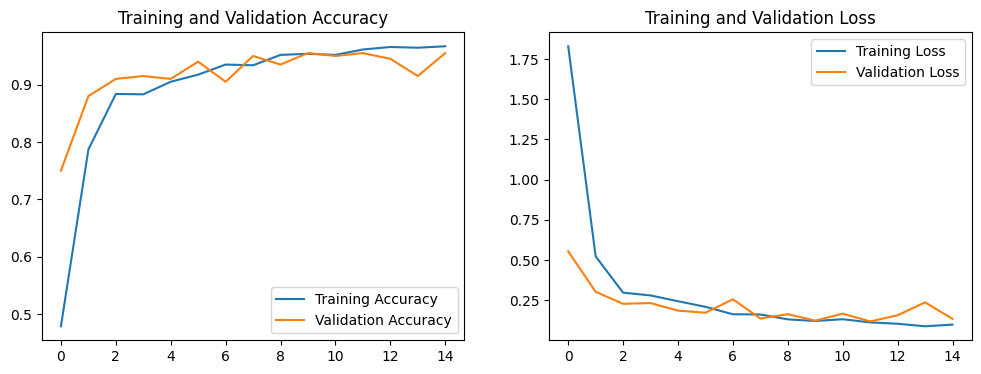

In [90]:
plot_training_history(history)

In [91]:
best_model = models.load_model(checkpoint_path)

loss, accuracy = best_model.evaluate(test_ds)
print(f"Test Accuracy: {accuracy:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 22s 817ms/step - accuracy: 0.9195 - loss: 0.1781
Test Accuracy: 0.9450


In [92]:
y_pred_probs = best_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.concatenate([y for x, y in test_ds], axis=0)

7/7 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step 


In [93]:
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

              precision    recall  f1-score   support

     Healthy       0.93      0.84      0.88        50
 LungsCancer       1.00      1.00      1.00        50
   Pneumonia       1.00      1.00      1.00        50
       covid       0.85      0.94      0.90        50

    accuracy                           0.94       200
   macro avg       0.95      0.94      0.94       200
weighted avg       0.95      0.94      0.94       200



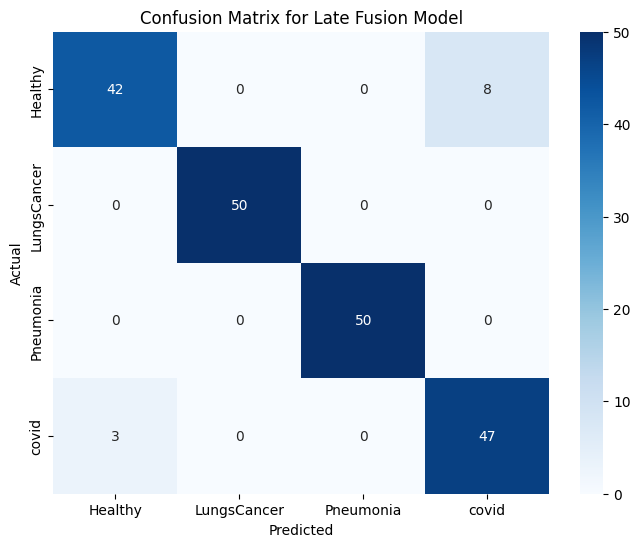

In [94]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Confusion Matrix for Late Fusion Model')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()